# 6 · Zonal statistics from KML

From one pixel to whole catchments: the **area-weighted mean** of every polygon in a KML
layer, and the **area-weighted quantiles** of the same. A cell half inside a zone carries
half the weight, and half the probability mass.

The layer here is [`catchments.kml`](../tests/resources/catchments.kml) — a QGIS export of
26 nested sub-catchments of the **Vesdre** basin in eastern Belgium, named by an `id`
field.

**Needs:** GDAL / `osgeo` (a conda package, deliberately not a pip dependency), plus
`matplotlib` for the figures.

In [1]:
import importlib.util
import sys
import tempfile
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Environment noise, nothing to do with meteoraster: xarray probes every NetCDF/GRIB
# backend it can find (cfgrib needs the ecCodes binary), and this conda env's h5py and
# HDF5 builds differ by a patch release.
warnings.filterwarnings('ignore', message='(?s).*ecCodes.*')
warnings.filterwarnings('ignore', message='(?s).*h5py is running against HDF5.*')

# Report warnings without their absolute path, so the committed output does not carry
# one machine's directory layout. The warnings themselves stay visible.
def brief_warning(message, category, filename, lineno, line=None):
    return '%s:%d: %s: %s\n' % (Path(filename).name, lineno, category.__name__, message)


warnings.formatwarning = brief_warning

# Run straight from a clone: if `meteoraster` is not installed in this environment,
# fall back to the repository root one level up.
if importlib.util.find_spec('meteoraster') is None:
    sys.path.insert(0, str(Path('..').resolve()))

from meteoraster import MeteoRaster, zonal

RESOURCES = Path('..') / 'tests' / 'resources'
KML = str(RESOURCES / 'catchments.kml')
NAME_FIELD = 'id'

plt.rcParams['figure.dpi'] = 100
pd.set_option('display.width', 120)
pd.set_option('display.max_columns', 10)

rain = MeteoRaster.load(RESOURCES / 'tethys_NOAA_GFS_0.25_2026.02.02.nct', verbose=False)

## The polygons

`zonal.read_kml_polygons` parses the KML into `(name, ogr.Geometry)` pairs. It is
namespace-agnostic, handles `<MultiGeometry>` wrappers and inner rings, and never touches
the input file. `name_field` names an `<ExtendedData>` field; with `None` the zones are
numbered by position.

In [2]:
polygons = zonal.read_kml_polygons(KML, name_field=NAME_FIELD)

print('%d zones\n' % len(polygons))
print(', '.join(name for name, _ in polygons))

26 zones

Chaudfontaine, Aval Magne, Mosbeux, Station Foret (Magne), Vaux, Pepinster, Station Verviers, Dison, Theux, Mangombroux, SPIXHE, R. Villers, Ruyff Baelen, Aval Gileppe, Polleur, Bach, BV Barrage Gileppe, Eupen aval conf. Helle, BV Barrage Vesdre, ss 22, ss 23, ss 24, BV Soor, Belleheid, ss 25, BV Helle


## The coverage

`coverage_from_kml` intersects each polygon with each grid cell and stores, per zone, the
cells it touches and their weights — a sparse structure, not a dense mask. The weights come
from **exact fractional overlap**, so a cell 30 % inside a zone gets 0.3 of its area.

In [3]:
coverage = zonal.coverage_from_kml(KML, rain.latitudes, rain.longitudes, name_field=NAME_FIELD)

print('zones          :', len(coverage))
print('grid           : %d x %d' % coverage.shape)
print('cells recorded :', coverage.cell_count, '(against %d in the full grid)'
      % (coverage.shape[0] * coverage.shape[1]))
print('empty zones    :', coverage.empty_zones())

zones          : 26
grid           : 29 x 57
cells recorded : 44 (against 1653 in the full grid)
empty zones    : []


What one zone's weights actually look like. `cells(i)` gives flat `row * cols + col`
indices and the matching weights, which sum to 1 under the default `normalize='area'`:

In [4]:
def zone_weights(coverage, raster, name):
    index, weight = coverage.cells(coverage.zones.index(name))
    row, col = np.unravel_index(index, coverage.shape)
    return pd.DataFrame({
        'row': row, 'col': col,
        'lat': raster.latitudes[row, col],
        'lon': raster.longitudes[row, col],
        'weight': weight.round(4),
    })


cells_per_zone = pd.Series({zone: len(coverage.cells(i)[0])
                            for i, zone in enumerate(coverage.zones)}, name='cells')
widest, narrowest = cells_per_zone.idxmax(), cells_per_zone.idxmin()

print('%d distinct grid cells carry the whole layer.' % len(np.unique(coverage.cell_index)))
print('cells per zone: min %d, max %d\n' % (cells_per_zone.min(), cells_per_zone.max()))
print('zone %r spreads over the most cells, and its weights sum to 1:' % widest)
zone_weights(coverage, rain, widest)

6 distinct grid cells carry the whole layer.
cells per zone: min 1, max 4

zone 'Dison' spreads over the most cells, and its weights sum to 1:


,row,col,lat,lon,weight
0,13,31,50.75,5.75,0.3893
1,13,32,50.75,6.00,0.0775
2,14,31,50.50,5.75,0.4865
3,14,32,50.50,6.00,0.0467


Most zones are not so lucky. On a 0.25° grid the majority of these catchments are smaller
than a single cell, so their "area-weighted mean" is one cell at weight 1:

In [5]:
print('zone %r sits entirely inside one cell:' % narrowest)
zone_weights(coverage, rain, narrowest)

zone 'Chaudfontaine' sits entirely inside one cell:


,row,col,lat,lon,weight
0,14,31,50.5,5.75,1.0


## Means per catchment

`get_values_from_KML` does the whole thing in one call: build the coverage, apply it, and
label the result.

In [6]:
means, centroids = rain.get_values_from_KML(kml=KML, nameField=NAME_FIELD)

print('frame  :', means.shape, ' = %d zones x %d leadtimes' % (len(coverage), len(rain.leadtimes)))
print('index  :', means.index.name)
print('columns:', means.columns.names)
means.iloc[:, :6].round(3)

frame  : (7, 3354)  = 26 zones x 129 leadtimes
index  : Production date
columns: ['zone', 'leadtime']


zone              Chaudfontaine                                                                                
leadtime        0 days 00:00:00 0 days 03:00:00 0 days 06:00:00 0 days 09:00:00 0 days 12:00:00 0 days 15:00:00
Production date                                                                                                
2026-02-02                0.138           0.207           0.009           0.000           0.000           0.000
2026-02-03                0.000           0.000           0.000           0.873           0.017           0.376
2026-02-04                0.000           0.000           0.000           0.000           0.000           0.000
2026-02-05                0.000           0.000           0.000           0.000           0.000           0.000
2026-02-06                0.000           0.285           0.060           0.130           0.091           0.000
2026-02-07                  NaN             NaN             NaN             NaN             NaN             NaN
2026-02-08                0.000           0.000           0.000           0.000           0.000           0.000

The columns are a MultiIndex over the surviving levels of
`(zone, leadtime, ensemble_member)` — size-1 levels are dropped, except `zone`, which is
always kept. This file is deterministic, so the member level is gone.

`centroids` comes back alongside, indexed by zone:

In [7]:
centroids.head()

,x,y
Chaudfontaine,5.663819,50.593520
Aval Magne,5.669437,50.568598
Mosbeux,5.703037,50.546920
Station Foret (Magne),5.746838,50.615286
Vaux,5.772020,50.579964


## Resolution matters — check before you plot

Before drawing 26 curves, ask whether they are 26 *different* curves. On a **0.25° grid**
most of these catchments are smaller than one cell, so several of them average exactly the
same cell and return byte-identical series.

In [8]:
one_leadtime = means.xs(pd.Timedelta(hours=24), level='leadtime', axis=1)

# One printable signature per zone: the whole series rounded and joined. NaN prints as
# 'nan', so the missing production groups consistently instead of never matching itself.
groups = {}
for zone, series in zip(one_leadtime.columns, one_leadtime.to_numpy(dtype=float).T):
    groups.setdefault('|'.join('%.6f' % value for value in series), []).append(zone)

shared = [zones for zones in groups.values() if len(zones) > 1]
duplicates = sum(len(zones) for zones in shared) - len(shared)

print('%d of %d zone series are exact duplicates of another zone.\n' % (duplicates, len(coverage)))
pd.DataFrame({
    'zones returning an identical series': [', '.join(z) for z in shared],
    'zones': [len(z) for z in shared],
})

10 of 26 zone series are exact duplicates of another zone.



,zones returning an identical series,zones
0,"Chaudfontaine, Aval Magne, Mosbeux, Vaux, Pepi...",6
1,"Aval Gileppe, BV Barrage Gileppe, ss 22, ss 23...",6


Now plot them knowing that. Two catchments from the same group are drawn deliberately —
the thin dashed line lies exactly on the thick one, because they *are* the same numbers.

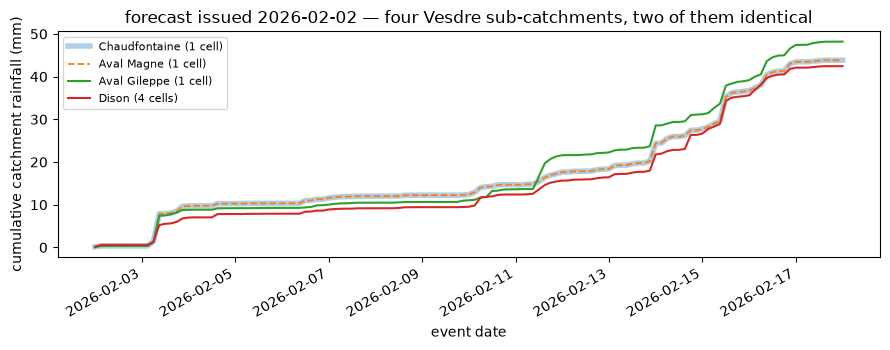

In [9]:
issue = means.index[0]
leads = pd.to_timedelta(means.columns.get_level_values('leadtime').unique())
show = [(shared[0][0], 4.0, '-', 0.35), (shared[0][1], 1.3, '--', 1.0),
        (shared[1][0], 1.5, '-', 1.0), (widest, 1.5, '-', 1.0)]

fig, ax = plt.subplots(figsize=(9, 3.6))
for zone, width, style, alpha in show:
    ax.plot(issue + leads, np.cumsum(means.loc[issue, zone].values),
            lw=width, ls=style, alpha=alpha, label='%s (%d cell%s)'
            % (zone, cells_per_zone[zone], 's' if cells_per_zone[zone] > 1 else ''))

ax.set(xlabel='event date', ylabel='cumulative catchment rainfall (mm)',
       title='forecast issued %s — four Vesdre sub-catchments, two of them identical'
             % issue.strftime('%Y-%m-%d'))
ax.legend(fontsize=8)
fig.autofmt_xdate()
fig.tight_layout()

It gets worse on a coarser grid. The ECMWF SEAS5 fixture is 1°, on which the entire Vesdre
basin needs a single row of cells:

In [10]:
seas5 = MeteoRaster.load(RESOURCES / 'tethys_c3s_ecmwf51_tprate_2026.07.nct', verbose=False)
coarse = zonal.coverage_from_kml(KML, seas5.latitudes, seas5.longitudes, name_field=NAME_FIELD)

comparison = pd.DataFrame({
    'grid': ['NOAA GFS 0.25°', 'ECMWF SEAS5 1°'],
    'cells per zone (min–max)': [
        '%d–%d' % (min(len(coverage.cells(i)[0]) for i in range(len(coverage))),
                   max(len(coverage.cells(i)[0]) for i in range(len(coverage)))),
        '%d–%d' % (min(len(coarse.cells(i)[0]) for i in range(len(coarse))),
                   max(len(coarse.cells(i)[0]) for i in range(len(coarse)))),
    ],
    'zones inside a single cell': [
        sum(len(coverage.cells(i)[0]) == 1 for i in range(len(coverage))),
        sum(len(coarse.cells(i)[0]) == 1 for i in range(len(coarse))),
    ],
})
comparison.set_index('grid')

,cells per zone (min–max),zones inside a single cell
grid,,
NOAA GFS 0.25°,1–4,12
ECMWF SEAS5 1°,1–2,20


> **Take-away:** zonal aggregation is only as informative as the grid underneath it.
> Resample onto a finer grid *before* aggregating if the zones are near or below the cell
> size — otherwise distinct catchments silently return the same number.

## Quantiles per catchment

`get_quantiles_from_KML` gives the **spatial distribution** inside each zone rather than
its mean, area-weighted exactly: a cell covering 30 % of the zone carries 30 % of the
probability mass.

Crop the leadtimes first — there is no reason to compute 129 of them for a demonstration.

In [11]:
three_days = rain.get_cropped(to_leadtime=pd.Timedelta(hours=72))

quantiles, _ = three_days.get_quantiles_from_KML(
    kml=KML, nameField=NAME_FIELD, quantiles=[0.1, 0.5, 0.9])

print('frame  :', quantiles.shape)
print('columns:', quantiles.columns.names)
quantiles.loc[:, ('Chaudfontaine', slice(None), slice(None))].iloc[:, :6].round(3)

frame  : (7, 1950)
columns: ['zone', 'leadtime', 'quantile']


zone              Chaudfontaine                                            
leadtime        0 days 00:00:00               0 days 03:00:00              
quantile                    0.1    0.5    0.9             0.1    0.5    0.9
Production date                                                            
2026-02-02                0.138  0.138  0.138           0.207  0.207  0.207
2026-02-03                0.000  0.000  0.000           0.000  0.000  0.000
2026-02-04                0.000  0.000  0.000           0.000  0.000  0.000
2026-02-05                0.000  0.000  0.000           0.000  0.000  0.000
2026-02-06                0.000  0.000  0.000           0.285  0.285  0.285
2026-02-07                  NaN    NaN    NaN             NaN    NaN    NaN
2026-02-08                0.000  0.000  0.000           0.000  0.000  0.000

For a zone that sits inside a single cell all three quantiles are identical — the sample
has one value in it. That is the resolution problem again, and it shows up cleanly as a
spread of exactly zero:

In [12]:
spread = (quantiles.xs(0.9, level='quantile', axis=1)
          - quantiles.xs(0.1, level='quantile', axis=1))

pd.DataFrame({
    'cells in zone': cells_per_zone,
    'widest q90-q10 ever seen': spread.T.groupby(level='zone').max().max(axis=1).round(3),
}).sort_values(['cells in zone', 'widest q90-q10 ever seen'])

,cells in zone,widest q90-q10 ever seen
Aval Gileppe,1,0.000
Aval Magne,1,0.000
BV Barrage Gileppe,1,0.000
BV Soor,1,0.000
Belleheid,1,0.000
Chaudfontaine,1,0.000
Mosbeux,1,0.000
Pepinster,1,0.000
Station Verviers,1,0.000
Vaux,1,0.000


### Pooling

By default `pool=('space',)`: one distribution per (production, member, leadtime), built
from the zone's cells. You can fold other axes into the sample too.

`'space'` is always required. The time axis has to be named explicitly — `'leadtime'` for a
forecast, `'production'` for an observation raster — because the event time is
`production + leadtime`, so "time" is a different axis depending on the layout.

`resampling` is the **block size** inside the pooled time axis, not a relabelling. Here it
pools every 3-hourly value in a zone across each day into one distribution:

In [13]:
daily, _ = three_days.get_quantiles_from_KML(
    kml=KML, nameField=NAME_FIELD, quantiles=[0.1, 0.5, 0.9],
    pool=('space', 'leadtime'), resampling='1D')

print('columns:', daily.columns.names)
daily.loc[:, ('Chaudfontaine', slice(None), slice(None))].iloc[:, :9].round(3)

columns:

 ['zone', 'leadtime', 'quantile']


zone            Chaudfontaine                                                        
leadtime               0 days               1 days               2 days              
quantile                  0.1    0.5    0.9    0.1    0.5    0.9    0.1    0.5    0.9
Production date                                                                      
2026-02-02                0.0  0.000  0.187    0.0  0.311  4.891    0.0  0.000  0.376
2026-02-03                0.0  0.015  0.790    0.0  0.000  0.000    0.0  0.000  0.018
2026-02-04                0.0  0.000  0.000    0.0  0.004  0.140    0.0  0.013  0.696
2026-02-05                0.0  0.000  0.000    0.0  0.011  0.121    0.0  0.000  0.012
2026-02-06                0.0  0.043  0.238    0.0  0.000  0.027    0.0  0.000  0.054
2026-02-07                NaN    NaN    NaN    NaN    NaN    NaN    NaN    NaN    NaN
2026-02-08                0.0  0.000  0.000    0.0  0.000  0.000    0.0  0.000  0.045

Each day now carries a distribution over `cells × 8 three-hourly steps`, so the 90th
percentile means "the wet corner of this catchment, at the wet hour of this day".

## Reusing a coverage

Intersecting polygons with a grid is the expensive part, and it depends only on the
geometry and the grid — not on the data. Compute it once.

In [14]:
_, _, coverage_info = rain.get_values_from_KML(kml=KML, nameField=NAME_FIELD,
                                               getCoverageInfo=True)

again, _ = rain.get_values_from_KML(kml=KML, coverage_info=coverage_info)
print('same numbers as before:', np.allclose(again.values, means.values, equal_nan=True))

same numbers as before: True


The lower-level API needs no `MeteoRaster` at all — it takes plain arrays whose last two
axes are `(y, x)`, so you can stream a file too large to load (notebook 2) and aggregate it
block by block, or feed geometry straight out of PostGIS as WKB or WKT.

In [15]:
direct = zonal.apply_coverage(coverage, rain.data)
print('apply_coverage:', rain.data.shape, '->', direct.shape, ' (y, x collapsed to zone)')

apply_coverage: (7, 1, 129, 29, 57) -> (7, 1, 129, 26)  (y, x collapsed to zone)


And a coverage can be saved to a pickle-free `.npz` and checked against a grid later.
`matches` hashes the **coordinates**, not just the shape — so a grid that keeps its shape
but shifts its geolocation is correctly reported as a miss.

In [16]:
with tempfile.TemporaryDirectory() as tmp:
    path = Path(tmp) / 'vesdre_on_gfs.npz'
    coverage.save(path)
    restored = zonal.Coverage.load(path)

    print('file size      : %.1f kB' % (path.stat().st_size / 1e3))
    print('zones restored :', len(restored))
    print('matches GFS    :', restored.matches(rain.latitudes, rain.longitudes))
    print('matches SEAS5  :', restored.matches(seas5.latitudes, seas5.longitudes))

file size      : 2.8 kB
zones restored : 26
matches GFS    : True
matches SEAS5  : False


## Where the catchments are

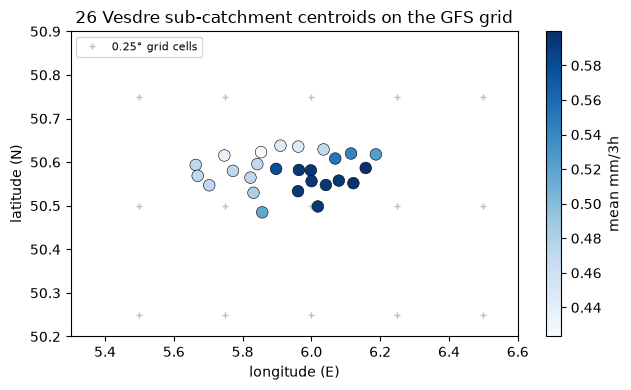

In [17]:
mean_rain = means.T.groupby(level='zone').mean().mean(axis=1)   # one number per catchment

fig, ax = plt.subplots(figsize=(6.5, 4))

ax.plot(rain.longitudes.ravel(), rain.latitudes.ravel(), '+', color='0.75', ms=4,
        label='0.25° grid cells')
scatter = ax.scatter(centroids['x'], centroids['y'], c=mean_rain[centroids.index],
                     cmap='Blues', edgecolor='k', linewidth=0.4, s=70, zorder=3)
fig.colorbar(scatter, ax=ax, label='mean %s' % rain.units)

ax.set(xlim=(5.3, 6.6), ylim=(50.2, 50.9),
       xlabel='longitude (E)', ylabel='latitude (N)',
       title='26 Vesdre sub-catchment centroids on the GFS grid')
ax.legend(fontsize=8, loc='upper left')
fig.tight_layout()

In [18]:
print('%d catchments, sharing %d distinct grid cells between them.'
      % (len(coverage), len(np.unique(coverage.cell_index))))
print('That is the picture behind the duplicate series above.')

26 catchments, sharing 6 distinct grid cells between them.
That is the picture behind the duplicate series above.


---
**Next:** [07 · Resampling](07_resampling.ipynb), which picks these catchment series up
and changes their time step.